# 35 — GWOSC data-quality flags (CAT1/CAT2) as vetoes: effect on the glitch floor

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extension 42. The GWOSC data-quality flags `H1_CBC_CAT1` and `H1_CBC_CAT2` (segments that remain *after* applying that category of vetoes) are queried for each of the eight O1 chunks; a one-second window is vetoed if it is not entirely inside a CAT2 segment. For the sine-Gaussian bank statistic and the fresh-injection CNN it measures (i) the dead time introduced, (ii) the share of the loudest background windows that the flags remove, (iii) the leave-one-chunk-out calibration of the FAP (notebook 23) before and after the veto, and (iv) the thresholds and the sensitivity gain at FAP 10⁻² and 10⁻³.

**What it does not do.** The flags are defined for CBC searches (`H1_BURST_CAT2` is reported where different); only what GWOSC publishes is available, not the full instrumental channels (Gravity Spy, auxiliary-channel vetoes); real events were excluded from the chunks, so nothing here can say whether the flags would veto a real signal.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from gwosc import timeline
import seq_models as sm
import gwosc_tools as g
g.style()
tf, keras, L = sm._tf()
CHK = g.chunks(); NCH = len(CHK)
FLAGS = ["H1_CBC_CAT1", "H1_CBC_CAT2", "H1_BURST_CAT2"]
SEG = {(i, f): timeline.get_segments(f, c["gps_start"], c["gps_start"] + c["duration"]) for i, c in enumerate(CHK) for f in FLAGS}
def good(i, flag):
    c = CHK[i]; n = len(g.load_chunk(i)["v"]); t0 = c["gps_start"] + g.TRIM + np.arange(n); ok = np.zeros(n, bool)
    for a, b in SEG[(i, flag)]: ok |= (t0 >= a) & (t0 + 1 <= b)
    return ok
GOOD = {(i, f): good(i, f) for i in range(NCH) for f in FLAGS}
print(pd.DataFrame({f: [1 - GOOD[(i, f)].mean() for i in range(NCH)] for f in FLAGS}, index=range(NCH)).round(4).T)

                 0    1      2    3       4    5       6       7
H1_CBC_CAT1    0.0  0.0  0.000  0.0  0.0000  0.0  0.0000  0.0000
H1_CBC_CAT2    0.0  0.0  0.074  0.0  0.0005  0.0  0.0007  0.0005
H1_BURST_CAT2  0.0  0.0  0.000  0.0  0.0020  0.0  0.0020  0.0020


In [2]:
def cscan(n): d = np.load(os.path.join(g.CACHE, f"scan03_{n}.npz")); return d["rho2"]
BANK, CNN = {}, {}
nets = [sm.train_variant("cnn_fresh", None, None, seed=s, verbose=False)[0] for s in range(5)]
for sp in ("train", "val", "test"):
    v, cid, _ = g.load_split(sp); r = cscan(sp)
    for c in np.unique(cid):
        m = cid == c; BANK[c] = r[m]; CNN[c] = np.mean([net.predict(sm.clip(v[m])[..., None], verbose=0, batch_size=1024)[:, 0] for net in nets], 0)
def cp(k, n, cl=0.6827): a = (1 - cl) / 2; return (stats.beta.ppf(a, k, n - k + 1) if k > 0 else 0.0, stats.beta.ppf(1 - a, k + 1, n - k))
rows = []
for flag in (None, "H1_CBC_CAT1", "H1_CBC_CAT2"):
    keep = {c: (GOOD[(c, flag)] if flag else np.ones(len(BANK[c]), bool)) for c in BANK}
    for det, D in (("bank", BANK), ("CNN", CNN)):
        for far in (1e-2, 1e-3):
            ratios = []
            for c in sorted(D):
                other = np.concatenate([D[k][keep[k]] for k in D if k != c]); thr = g.threshold_at_far(other, far); ratios.append(float((D[c][keep[c]] > thr).mean() / far))
            allv = np.concatenate([D[k][keep[k]] for k in D])
            rows.append(dict(veto=flag or "none", detector=det, FAP=far, dead_time=float(1 - np.mean(np.concatenate([keep[k] for k in keep]))), ratio_min=min(ratios), ratio_max=max(ratios), ratio_spread_log=float(np.std(np.log(np.maximum(ratios, 1e-3)))), threshold=g.threshold_at_far(allv, far)))
R = pd.DataFrame(rows); R.round(3)

,veto,detector,FAP,dead_time,ratio_min,ratio_max,ratio_spread_log,threshold
0,none,bank,0.010,0.000,0.296,4.290,0.742,30.095
1,none,bank,0.001,0.000,0.493,4.931,0.728,110.294
2,none,CNN,0.010,0.000,0.074,3.994,1.293,0.865
3,none,CNN,0.001,0.000,0.000,4.191,3.581,2.809
4,H1_CBC_CAT1,bank,0.010,0.000,0.296,4.290,0.742,30.095
5,H1_CBC_CAT1,bank,0.001,0.000,0.493,4.931,0.728,110.294
6,H1_CBC_CAT1,CNN,0.010,0.000,0.074,3.994,1.293,0.865
7,H1_CBC_CAT1,CNN,0.001,0.000,0.000,4.191,3.581,2.809
8,H1_CBC_CAT2,bank,0.010,0.009,0.764,1.209,0.150,28.427
9,H1_CBC_CAT2,bank,0.001,0.009,0.266,1.480,0.574,57.032


In [3]:
# how many of the loudest background windows do the flags remove?
rows = []
for det, D in (("bank", BANK), ("CNN", CNN)):
    allv = np.concatenate([D[c] for c in sorted(D)]); gg = {f: np.concatenate([GOOD[(c, f)] for c in sorted(D)]) for f in FLAGS}
    for q in (0.99, 0.999, 0.9995):
        top = allv > np.quantile(allv, q); rows.append(dict(detector=det, top_fraction=1 - q, n=int(top.sum()), **{f"removed_by_{f}": float((~gg[f][top]).mean()) for f in FLAGS}, dead_time_CAT2=float((~gg["H1_CBC_CAT2"]).mean())))
TOP = pd.DataFrame(rows); TOP.round(3)

,detector,top_fraction,n,removed_by_H1_CBC_CAT1,removed_by_H1_CBC_CAT2,removed_by_H1_BURST_CAT2,dead_time_CAT2
0,bank,0.010,325,0.0,0.400,0.046,0.009
1,bank,0.001,33,0.0,0.394,0.273,0.009
2,bank,0.000,17,0.0,0.353,0.412,0.009
3,CNN,0.010,325,0.0,0.040,0.003,0.009
4,CNN,0.001,33,0.0,0.030,0.000,0.009
5,CNN,0.000,17,0.0,0.000,0.000,0.009


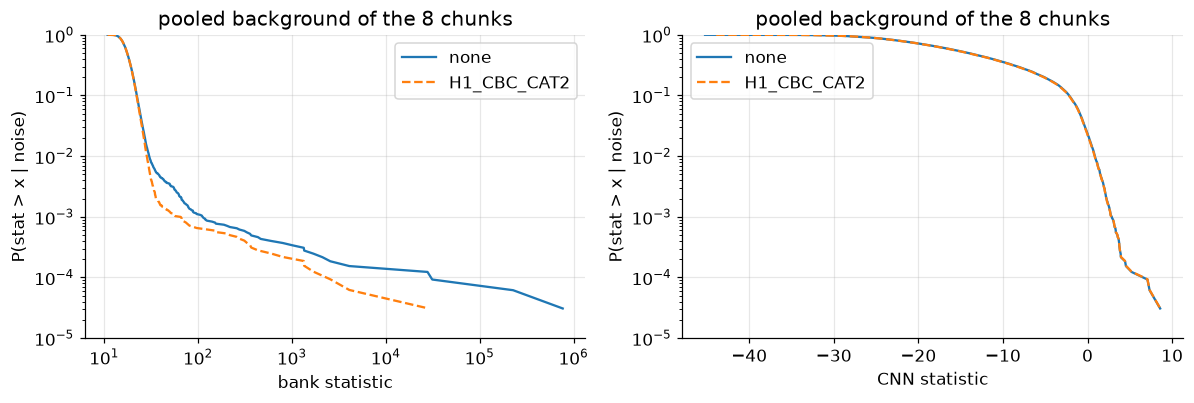

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, (det, D) in zip(ax, (("bank", BANK), ("CNN", CNN))):
    for flag, ls in (("none", "-"), ("H1_CBC_CAT2", "--")):
        keep = {c: (GOOD[(c, flag)] if flag != "none" else np.ones(len(D[c]), bool)) for c in D}; x = np.sort(np.concatenate([D[c][keep[c]] for c in D])); a.semilogy(x, 1 - np.arange(len(x)) / len(x), ls=ls, label=flag)
    a.set_xscale("symlog" if det == "bank" else "linear"); a.set_xlabel(f"{det} statistic"); a.set_ylabel("P(stat > x | noise)"); a.set_ylim(1e-5, 1); a.legend(); a.set_title("pooled background of the 8 chunks")
fig.tight_layout(); g.savefig(fig, "fig35_dq_flags"); plt.show()
g.save_json(dict(calibration=R.to_dict("records"), top_windows=TOP.to_dict("records"), dead_time={f: [float(1 - GOOD[(i, f)].mean()) for i in range(NCH)] for f in FLAGS}), "35_summary.json")

## Output and next step

`results/35_summary.json`, `figures/fig35_dq_flags`. Next: generalisation of the detectors to O2 and O3.